# LAB 12 — Artificial Neural Networks: The Perceptron
## Student Information
- **Name:** Ghulam Mustafa
- **Roll No / CMS ID:** 023-24-0212
- **Section:** G
- **Date:** 17 November 2026
- **GitHub Repo:** https://github.com/mustafaa101/Machine-learning

**Dataset:** Iris (sklearn built-in) · Use `random_state=42` everywhere · Write a 1–2 sentence interpretation under every plot and table.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, make_classification
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

np.random.seed(42)
iris = load_iris()
print("Iris loaded:", iris.data.shape, "| Classes:", iris.target_names)

Iris loaded: (150, 4) | Classes: ['setosa' 'versicolor' 'virginica']


## Part 1 — The Neuron From Scratch

### Task 1.1 — Weighted sum, step function and predict
Write `weighted_sum`, `step_function`, `predict`. Verify slide 16 (`predict([0.6,0.8],[2,3],-2)` → 1) and slide 17 (w=[1,−0.5], b=0.5; inputs [1,1],[2,1],[0,3] → 1, 1, 0).

In [2]:
# Task 1.1
def weighted_sum(w, x, b):
    """z = w . x + b"""
    return np.dot(w, x) + b

def step_function(z):
    """1 if z >= 0 else 0"""
    return 1 if z >= 0 else 0

def predict(w, x, b):
    return step_function(weighted_sum(w, x, b))

# Slide 16 check
print("Slide 16: z =", weighted_sum([0.6, 0.8], [2, 3], -2), "| y_hat =", predict([0.6, 0.8], [2, 3], -2), "(expected 1)")

# Slide 17 check
w17, b17 = [1, -0.5], 0.5
expected = [1, 1, 0]
for x, e in zip([[1, 1], [2, 1], [0, 3]], expected):
    print(f"Slide 17: x={x} -> z={weighted_sum(w17, x, b17):.2f}, y_hat={predict(w17, x, b17)} (expected {e})")

Slide 16: z = 1.6 | y_hat = 1 (expected 1)
Slide 17: x=[1, 1] -> z=1.00, y_hat=1 (expected 1)
Slide 17: x=[2, 1] -> z=2.00, y_hat=1 (expected 1)
Slide 17: x=[0, 3] -> z=-1.00, y_hat=0 (expected 0)


**Check:** all four results match the lecture slides — slide 16 gives z = 1.6 → ŷ = 1, and slide 17 gives ŷ = 1, 1, 0. This confirms `weighted_sum`, `step_function` and `predict` are correct.

### Task 1.2 — One full epoch on the AND gate, by hand
AND: (0,0,0), (0,1,0), (1,0,0), (1,1,1). Start w=[0.2, −0.1], b=0, η=0.1. Print z, ŷ, e and the new w, b for each row; then the mistake count and "Converged!" / "Keep training.".

In [3]:
# Task 1.2
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])

w = np.array([0.2, -0.1]); b = 0.0; eta = 0.1; mistakes = 0
print(f"Start: w={w}, b={b}, eta={eta}\n")
for i, (x, y) in enumerate(zip(X_and, y_and), 1):
    z = weighted_sum(w, x, b)
    y_hat = step_function(z)
    e = y - y_hat
    if e != 0:
        mistakes += 1
    w = w + eta * e * x          # weight changes only where x_i != 0
    b = b + eta * e
    print(f"Row {i}: x={x}, y={y} | z={z:+.2f}, y_hat={y_hat}, e={e:+d} | new w={np.round(w, 2)}, new b={b:+.2f}")

print(f"\nFinal w = {np.round(w, 2)}, b = {b:.2f}, mistakes = {mistakes}")
print("Converged!" if mistakes == 0 else "Keep training.")

Start: w=[ 0.2 -0.1], b=0.0, eta=0.1

Row 1: x=[0 0], y=0 | z=+0.00, y_hat=1, e=-1 | new w=[ 0.2 -0.1], new b=-0.10
Row 2: x=[0 1], y=0 | z=-0.20, y_hat=0, e=+0 | new w=[ 0.2 -0.1], new b=-0.10
Row 3: x=[1 0], y=0 | z=+0.10, y_hat=1, e=-1 | new w=[ 0.1 -0.1], new b=-0.20
Row 4: x=[1 1], y=1 | z=-0.20, y_hat=0, e=+1 | new w=[0.2 0. ], new b=-0.10

Final w = [0.2 0. ], b = -0.10, mistakes = 3
Keep training.


**Interpretation:** Row 1 (0,0) is already a mistake because z = 0 counts as ŷ = 1, so only b changes (w is multiplied by x = 0). After the full epoch w = [0.2, 0.0], b = −0.1 with **3 mistakes**, so the output is "Keep training." — one epoch is not enough.

## Part 2 — Train a Perceptron From Scratch

### Task 2.1 — Implement `train_perceptron`
`train_perceptron(X, y, eta=0.1, max_epochs=100)`: start from zeros, update on every mistake, record mistakes per epoch, stop after a zero-mistake epoch. Train on OR (y = [0,1,1,1]) and print w, b.

In [4]:
# Task 2.1
def train_perceptron(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float); y = np.asarray(y)
    w = np.zeros(X.shape[1]); b = 0.0
    mistakes = []
    for epoch in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            y_hat = step_function(np.dot(w, xi) + b)
            e = yi - y_hat
            if e != 0:                       # update only on a mistake
                w = w + eta * e * xi
                b = b + eta * e
                errors += 1
        mistakes.append(errors)
        if errors == 0:                      # stop after a zero-mistake epoch
            break
    return w, b, mistakes

X_gate = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_or = np.array([0, 1, 1, 1])
w_or, b_or, mistakes_or = train_perceptron(X_gate, y_or, eta=0.1, max_epochs=100)
print("OR gate -> w =", np.round(w_or, 3), "| b =", round(b_or, 3))
print("Mistakes per epoch:", mistakes_or)

OR gate -> w = [0.1 0.1] | b = -0.1
Mistakes per epoch: [2, 2, 1, 0]


**Interpretation:** Starting from zeros, the perceptron learns OR in 4 epochs with mistakes [2, 2, 1, 0], ending at w = [0.1, 0.1], b = −0.1. The last epoch has zero mistakes, so training stopped early as required.

### Task 2.2 — Plot mistakes per epoch
Title "Perceptron training on OR gate", axes "Epoch" / "Mistakes"; mark the final epoch with a red dot.

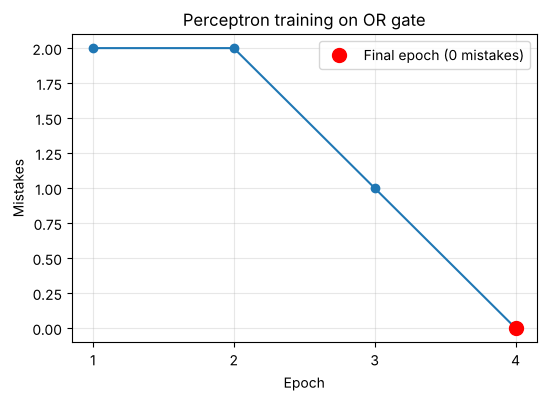

In [5]:
# Task 2.2
epochs = np.arange(1, len(mistakes_or) + 1)
plt.figure(figsize=(6, 4))
plt.plot(epochs, mistakes_or, marker="o", color="tab:blue")
plt.plot(epochs[-1], mistakes_or[-1], "ro", markersize=10, label="Final epoch (0 mistakes)")
plt.title("Perceptron training on OR gate")
plt.xlabel("Epoch"); plt.ylabel("Mistakes")
plt.xticks(epochs); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Interpretation:** The number of mistakes falls steadily (2 → 2 → 1 → 0) and reaches zero at epoch 4 (red dot), showing that the perceptron converges on a linearly separable problem like OR.

## Part 3 — The Decision Boundary

### Task 3.1 — Plot the OR gate with its boundary
Boundary: x₂ = −(w₁/w₂)x₁ − b/w₂ over `np.linspace(-0.5, 1.5, 100)`. Class 0 blue circles, class 1 red squares, boundary black dashed. Write a reusable `plot_boundary(ax, w, b)` that handles w₂ = 0.

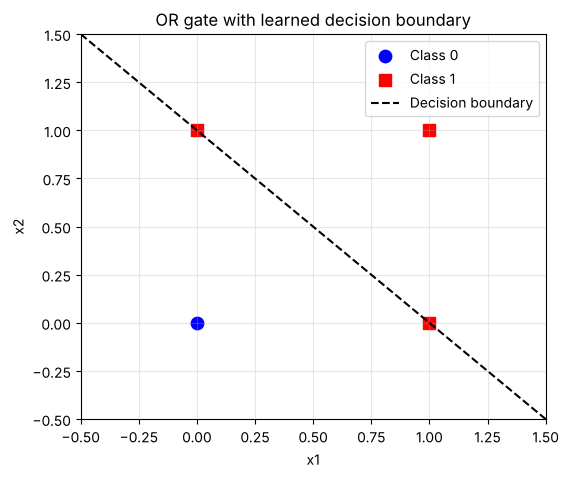

In [6]:
# Task 3.1
def plot_boundary(ax, w, b, x_range=(-0.5, 1.5), **kwargs):
    """Draw w1*x1 + w2*x2 + b = 0. Handles w2 = 0 (vertical line)."""
    kwargs.setdefault("color", "black"); kwargs.setdefault("linestyle", "--"); kwargs.setdefault("label", "Decision boundary")
    w1, w2 = w
    if w2 != 0:
        x1 = np.linspace(x_range[0], x_range[1], 100)
        x2 = -(w1 / w2) * x1 - b / w2
        ax.plot(x1, x2, **kwargs)
    elif w1 != 0:
        ax.axvline(-b / w1, **kwargs)      # vertical line x1 = -b / w1
    else:
        print("w = [0, 0]: no boundary to draw")

def scatter_classes(ax, X, y, names=("Class 0", "Class 1")):
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="blue", marker="o", s=80, label=names[0])
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="red", marker="s", s=80, label=names[1])

fig, ax = plt.subplots(figsize=(6, 5))
scatter_classes(ax, X_gate, y_or, ("Class 0", "Class 1"))
plot_boundary(ax, w_or, b_or)
ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
ax.set_title("OR gate with learned decision boundary")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Interpretation:** With w = [0.1, 0.1] and b = −0.1 the boundary is x₂ = −x₁ + 1. The side where z ≥ 0 (upper-right, away from the origin) is ŷ = 1; points (0,1) and (1,0) lie exactly on the line (z = 0 → ŷ = 1) and (1,1) is above it, while (0,0) is below it as class 0.

### Task 3.2 — With and without bias
Train both versions on X=[[1,0],[0,1],[2,1],[1,2]], y=[0,0,1,1]; plot the two boundaries side by side. Did the no-bias version converge?

With bias   : w=[0.1 0.1], b=-0.200, epochs=4, final mistakes=0
Without bias: w=[0.1 0. ], b=0.000, epochs=100, final mistakes=2
No-bias version converged? False


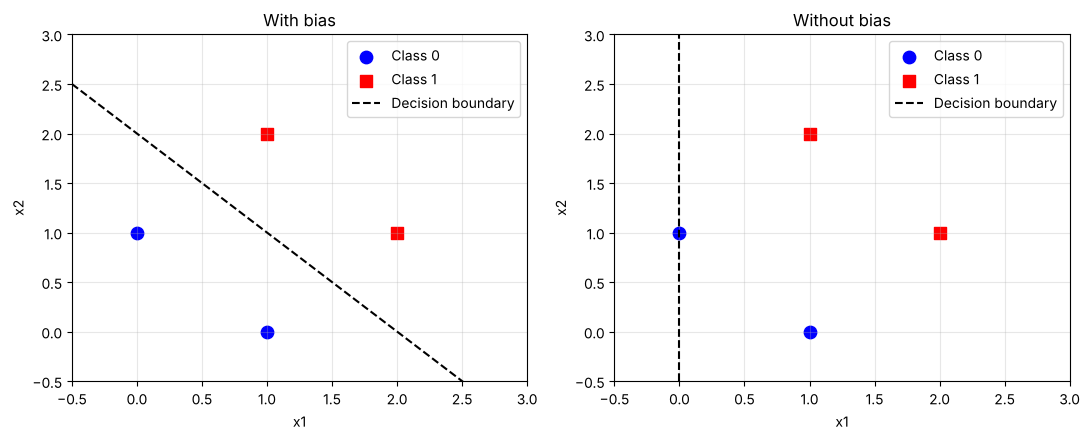

In [7]:
# Task 3.2
def train_perceptron_nobias(X, y, eta=0.1, max_epochs=100):
    X = np.asarray(X, dtype=float); y = np.asarray(y)
    w = np.zeros(X.shape[1]); b = 0.0          # b stays 0 and is never updated
    mistakes = []
    for epoch in range(max_epochs):
        errors = 0
        for xi, yi in zip(X, y):
            e = yi - step_function(np.dot(w, xi) + b)
            if e != 0:
                w = w + eta * e * xi
                errors += 1
        mistakes.append(errors)
        if errors == 0:
            break
    return w, b, mistakes

X_b = np.array([[1, 0], [0, 1], [2, 1], [1, 2]]); y_b = np.array([0, 0, 1, 1])
w_wb, b_wb, m_wb = train_perceptron(X_b, y_b, eta=0.1, max_epochs=100)
w_nb, b_nb, m_nb = train_perceptron_nobias(X_b, y_b, eta=0.1, max_epochs=100)
print(f"With bias   : w={np.round(w_wb, 3)}, b={b_wb:.3f}, epochs={len(m_wb)}, final mistakes={m_wb[-1]}")
print(f"Without bias: w={np.round(w_nb, 3)}, b={b_nb:.3f}, epochs={len(m_nb)}, final mistakes={m_nb[-1]}")
print("No-bias version converged?", m_nb[-1] == 0)

plt.figure(figsize=(11, 4.5))
for k, (title, w_, b_) in enumerate([("With bias", w_wb, b_wb), ("Without bias", w_nb, b_nb)], 1):
    ax = plt.subplot(1, 2, k)
    scatter_classes(ax, X_b, y_b)
    plot_boundary(ax, w_, b_, x_range=(-0.5, 3))
    ax.set_xlim(-0.5, 3); ax.set_ylim(-0.5, 3)
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation:** The version **with bias** converged in 4 epochs (w = [0.1, 0.1], b = −0.2) and separates the classes with a line that does not pass through the origin. The **no-bias** version did **not** converge (100 epochs, still 2 mistakes) because without b the boundary is forced through the origin, and no such line separates (1,0),(0,1) from (2,1),(1,2) — since (2,1) = 2·(1,0) + (0,1), w·(2,1) must be negative whenever both class-0 points are negative.

## Part 4 — The XOR Limitation

### Task 4.1 — Watch the perceptron fail
XOR: y = [0,1,1,0], `max_epochs=100`. Print final mistakes, w, b; plot mistakes per epoch and the boundary.

Epochs run: 100 | Final mistakes: 4
w = [-0.1  0. ] | b = 0.0
Min mistakes in any epoch: 3


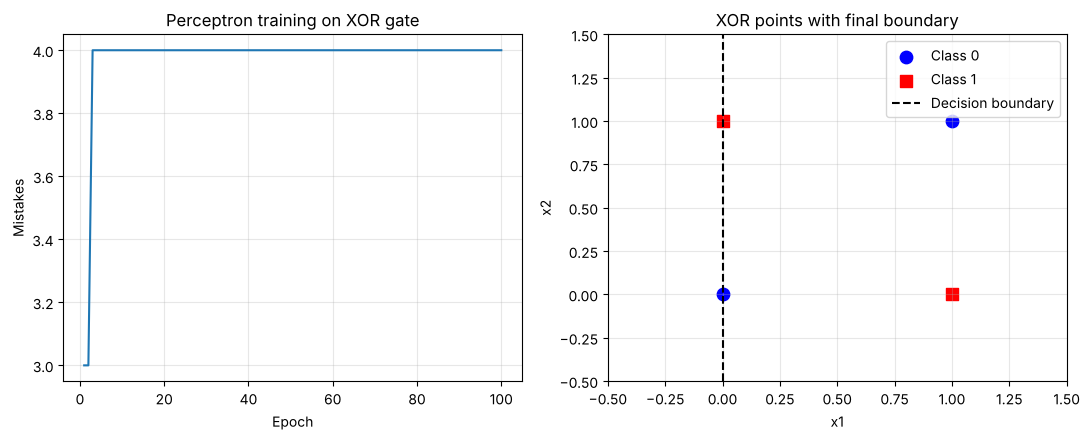

In [8]:
# Task 4.1
y_xor = np.array([0, 1, 1, 0])
w_x, b_x, m_x = train_perceptron(X_gate, y_xor, eta=0.1, max_epochs=100)
print("Epochs run:", len(m_x), "| Final mistakes:", m_x[-1])
print("w =", np.round(w_x, 3), "| b =", round(b_x, 3))
print("Min mistakes in any epoch:", min(m_x))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(range(1, len(m_x) + 1), m_x, color="tab:blue")
axes[0].set_title("Perceptron training on XOR gate"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Mistakes")
axes[0].grid(alpha=0.3)

scatter_classes(axes[1], X_gate, y_xor)
plot_boundary(axes[1], w_x, b_x)
axes[1].set_xlim(-0.5, 1.5); axes[1].set_ylim(-0.5, 1.5)
axes[1].set_title("XOR points with final boundary"); axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation:** The perceptron **never reaches zero mistakes** on XOR: after 100 epochs it still makes 4 mistakes (best epoch = 3), and it ends at w = [−0.1, 0], b = 0 (a vertical line at x₁ = 0). XOR is not linearly separable, so every update that fixes one point breaks another and the weights just keep cycling.

### Task 4.2 — Confirm no weight vector works
`check_xor(w, b)` returns True only if all four XOR constraints hold. Test 10,000 random (w₁, w₂, b) in [−5, 5].

In [9]:
# Task 4.2
def check_xor(w, b):
    """True only if all four XOR constraints hold."""
    return (np.dot(w, [0, 0]) + b < 0 and
            np.dot(w, [0, 1]) + b >= 0 and
            np.dot(w, [1, 0]) + b >= 0 and
            np.dot(w, [1, 1]) + b < 0)

np.random.seed(42)
W = np.random.uniform(-5, 5, (10000, 2))
B = np.random.uniform(-5, 5, 10000)
passing = [(W[i, 0], W[i, 1], B[i]) for i in range(10000) if check_xor(W[i], B[i])]
print("Triples tested:", 10000, "| Passing:", len(passing))
print("No solution found" if len(passing) == 0 else f"First passing triple: {passing[0]}")

Triples tested: 10000 | Passing: 0
No solution found


**Interpretation:** 0 of 10,000 random (w₁, w₂, b) triples satisfy all four XOR constraints ("No solution found"). This agrees with the algebraic proof in Q3: no single line (single perceptron) can compute XOR.

## Part 5 — scikit-learn Perceptron on Iris

### Task 5.1 — Train and evaluate
Petal features (2, 3), Setosa vs rest; 70/30 stratified split; `Perceptron(random_state=42)`. Print accuracy, confusion matrix, report, `coef_`, `intercept_`.

In [10]:
# Task 5.1
X_iris = iris.data[:, (2, 3)]                  # petal length, petal width
y_iris = (iris.target == 0).astype(int)        # Setosa vs rest
X_train, X_test, y_train, y_test = train_test_split(
    X_iris, y_iris, test_size=0.3, random_state=42, stratify=y_iris)

clf = Perceptron(random_state=42)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred, target_names=["Rest", "Setosa"]))
print("coef_     :", clf.coef_)
print("intercept_:", clf.intercept_)

Accuracy: 1.0

Confusion matrix:
 [[30  0]
 [ 0 15]]

Classification report:
               precision    recall  f1-score   support

        Rest       1.00      1.00      1.00        30
      Setosa       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45

coef_     : [[-1.3 -2.2]]
intercept_: [4.]


**Interpretation:** The perceptron separates Setosa from the rest perfectly on the test set: accuracy = 1.00 with a confusion matrix of [[30, 0], [0, 15]]. `coef_` = [−1.3, −2.2] are the weights w₁, w₂ and `intercept_` = 4.0 is the bias b from Part 1; both weights are negative because Setosa has small petals, so z ≥ 0 only for small petal length/width.

### Task 5.2 — Visualise the learned boundary
Boundary from `coef_[0]`, `intercept_[0]`; test set coloured by class; misclassified points as red ×.

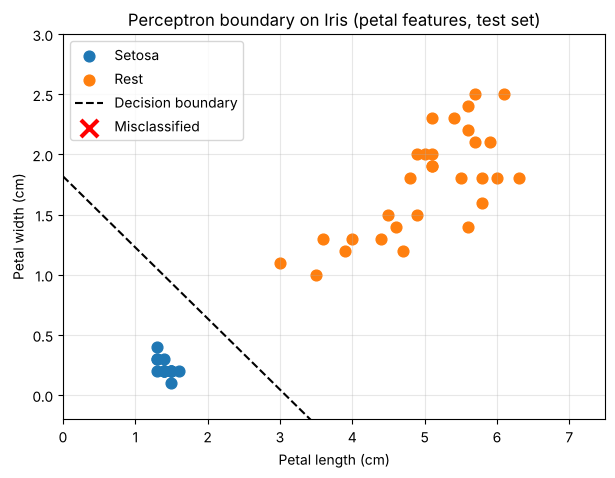

Misclassified test points: 0 out of 45


In [11]:
# Task 5.2
w_sk, b_sk = clf.coef_[0], clf.intercept_[0]
wrong = y_pred != y_test
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_test[y_test == 1, 0], X_test[y_test == 1, 1], c="tab:blue", label="Setosa", s=60)
ax.scatter(X_test[y_test == 0, 0], X_test[y_test == 0, 1], c="tab:orange", label="Rest", s=60)
plot_boundary(ax, w_sk, b_sk, x_range=(0, 7.5))
ax.scatter(X_test[wrong, 0], X_test[wrong, 1], c="red", marker="x", s=150, linewidths=3, label="Misclassified", zorder=5)
ax.set_xlim(0, 7.5); ax.set_ylim(-0.2, 3)
ax.set_title("Perceptron boundary on Iris (petal features, test set)")
ax.set_xlabel("Petal length (cm)"); ax.set_ylabel("Petal width (cm)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()
print("Misclassified test points:", int(wrong.sum()), "out of", len(y_test))

**Interpretation:** **0 of 45** test points are misclassified (no red ×), and the boundary −1.3x₁ − 2.2x₂ + 4 = 0 (≈ x₂ = −0.59x₁ + 1.82) is a straight line because z = 0 is linear in the inputs. Setosa is linearly separable from the other two species using petal features, which is why a single perceptron is enough.

### Task 5.3 — Effect of learning rate
`eta0` = 0.001, 0.1, 10.0. Table of eta0 | accuracy | `n_iter_` | `coef_`. Do the predictions change? What does η do when training starts from w = 0?

In [12]:
# Task 5.3
print(f"{'eta0':>8} | {'accuracy':>8} | {'n_iter_':>7} | coef_")
print("-" * 60)
preds = {}
coefs = {}
for eta0 in [0.001, 0.1, 10.0]:
    m = Perceptron(random_state=42, eta0=eta0).fit(X_train, y_train)
    preds[eta0] = m.predict(X_test); coefs[eta0] = m.coef_[0]
    print(f"{eta0:>8} | {accuracy_score(y_test, preds[eta0]):>8.3f} | {m.n_iter_:>7} | {np.round(m.coef_[0], 4)}  b={m.intercept_[0]:.4f}")

print("\nPredictions identical for all eta0?",
      np.array_equal(preds[0.001], preds[0.1]) and np.array_equal(preds[0.1], preds[10.0]))
print("coef ratios (eta0=0.1 / eta0=0.001):", np.round(coefs[0.1] / coefs[0.001], 2))
print("coef ratios (eta0=10  / eta0=0.1  ):", np.round(coefs[10.0] / coefs[0.1], 2))

    eta0 | accuracy | n_iter_ | coef_
------------------------------------------------------------
   0.001 |    1.000 |       6 | [-0.0013 -0.0022]  b=0.0040
     0.1 |    1.000 |       7 | [-0.13 -0.22]  b=0.4000
    10.0 |    1.000 |       7 | [-13. -22.]  b=40.0000

Predictions identical for all eta0? True
coef ratios (eta0=0.1 / eta0=0.001): [100. 100.]
coef ratios (eta0=10  / eta0=0.1  ): [100. 100.]


**Interpretation:** All three learning rates give accuracy 1.00 and **identical predictions**; `n_iter_` is 6, 7 and 7. The coefficients are exactly scaled copies of each other (≈ [−0.0013, −0.0022], [−0.13, −0.22], [−13, −22] — a factor of 100 each step), and the bias scales the same way (0.004, 0.4, 40). Since training starts from w = 0, every update is η·e·x, so η only rescales w and b and does not change the direction of the boundary or the predictions.

## Part 6 — Multi-Class Classification

### Task 6.1 — All three Iris classes
All four features, `y = iris.target`, 70/30 stratified; `Perceptron(random_state=42, max_iter=1000)`. Print report, confusion matrix, `coef_.shape`. Which class is hardest?

In [13]:
# Task 6.1
X_all, y_all = iris.data, iris.target
Xtr3, Xte3, ytr3, yte3 = train_test_split(X_all, y_all, test_size=0.3, random_state=42, stratify=y_all)
clf3 = Perceptron(random_state=42, max_iter=1000).fit(Xtr3, ytr3)
pred3 = clf3.predict(Xte3)
print("Classification report:\n", classification_report(yte3, pred3, target_names=iris.target_names, zero_division=0))
print("Confusion matrix:\n", confusion_matrix(yte3, pred3))
print("\ncoef_.shape:", clf3.coef_.shape)

Classification report:
               precision    recall  f1-score   support

      setosa       0.52      1.00      0.68        15
  versicolor       0.00      0.00      0.00        15
   virginica       0.94      1.00      0.97        15

    accuracy                           0.67        45
   macro avg       0.48      0.67      0.55        45
weighted avg       0.48      0.67      0.55        45

Confusion matrix:
 [[15  0  0]
 [14  0  1]
 [ 0  0 15]]

coef_.shape: (3, 4)


**Interpretation:** Accuracy is only **0.667** (macro-F1 = 0.55). `coef_.shape` = (3, 4): each row is the weight vector of one one-vs-rest perceptron (one class vs the other two) over the 4 features. **Versicolor is the hardest class** (recall = 0.00): the confusion matrix shows 14 of its 15 test flowers predicted as setosa and 1 as virginica, because versicolor sits between the other two classes and cannot be separated from "rest" by one straight line, so its perceptron never settles.

### Task 6.2 — Perceptron vs Logistic Regression
`LogisticRegression(random_state=42, max_iter=200)` on the same split; side-by-side accuracy and macro-F1; why can it win (slide 32)?

In [14]:
# Task 6.2
lr = LogisticRegression(random_state=42, max_iter=200).fit(Xtr3, ytr3)
pred_lr = lr.predict(Xte3)

print(f"{'Model':<22} | {'Accuracy':>8} | {'Macro-F1':>8}")
print("-" * 46)
for name, p in [("Perceptron", pred3), ("Logistic Regression", pred_lr)]:
    print(f"{name:<22} | {accuracy_score(yte3, p):>8.3f} | {f1_score(yte3, p, average='macro'):>8.3f}")
print("\nLogistic Regression confusion matrix:\n", confusion_matrix(yte3, pred_lr))

Model                  | Accuracy | Macro-F1
----------------------------------------------
Perceptron             |    0.667 |    0.550
Logistic Regression    |    0.933 |    0.933

Logistic Regression confusion matrix:
 [[15  0  0]
 [ 0 14  1]
 [ 0  2 13]]


**Interpretation:** Logistic Regression is clearly better here: accuracy 0.933 and macro-F1 0.933 versus 0.667 and 0.550 for the perceptron (only 3 errors vs 15). The sigmoid/softmax is smooth, so its gradient is never exactly zero and every sample keeps contributing to the update, while the step function only says "right" or "wrong" and cannot converge on overlapping classes such as versicolor and virginica.

## Part 7 — Graded Questions (5 marks)
Answer in the Markdown cells below, using your own numbers.

**Q1 [0.5 marks] — Manual update trace.** w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0. Compute z and ŷ, then e, then the updated w₁, w₂ and b.

**Q1 — Manual update trace** (w = [0.5, −0.3], b = 0.2, η = 0.1, x = [1, 2], y = 0)

- z = w₁x₁ + w₂x₂ + b = 0.5(1) + (−0.3)(2) + 0.2 = 0.5 − 0.6 + 0.2 = **0.1**
- ŷ = step(0.1) = **1** (wrong, since y = 0)
- e = y − ŷ = 0 − 1 = **−1**
- w₁ = 0.5 + 0.1(−1)(1) = **0.4**
- w₂ = −0.3 + 0.1(−1)(2) = **−0.5**
- b = 0.2 + 0.1(−1) = **0.1**

Check: new z = 0.4(1) + (−0.5)(2) + 0.1 = −0.5 → ŷ = 0, which is now correct.

In [15]:
# Q1 verification
w = np.array([0.5, -0.3]); b = 0.2; eta = 0.1; x = np.array([1, 2]); y = 0
z = weighted_sum(w, x, b); y_hat = step_function(z); e = y - y_hat
w_new = w + eta * e * x; b_new = b + eta * e
print(f"z = {z:.2f}, y_hat = {y_hat}, e = {e}")
print(f"new w = {np.round(w_new, 2)}, new b = {b_new:.2f}")
print("new prediction:", predict(w_new, x, b_new), "(target 0)")

z = 0.10, y_hat = 1, e = -1
new w = [ 0.4 -0.5], new b = 0.10
new prediction: 0 (target 0)


**Q2 [0.5 marks] — Boundary geometry.** After training on AND: w = [0.3, 0.2], b = −0.4. Write the boundary equation. Which side is (1, 1) on, and what is ŷ?

**Q2 — Boundary geometry** (w = [0.3, 0.2], b = −0.4)

- Boundary (z = 0): 0.3x₁ + 0.2x₂ − 0.4 = 0, i.e. **x₂ = −1.5x₁ + 2**.
- For (1, 1): z = 0.3 + 0.2 − 0.4 = **0.1 ≥ 0**, so (1, 1) lies on the **positive side** (above the line, since the line is at x₂ = 0.5 when x₁ = 1) and **ŷ = 1**.
- The other AND points give z = −0.4, −0.2, −0.1 (all < 0 → ŷ = 0), so this boundary classifies AND correctly.

**Q3 [1 mark] — XOR analysis.** (a) Show algebraically that the four XOR constraints cannot all hold. (b) Sketch XOR on x₁–x₂ axes (insert an image or a matplotlib plot) to show why no line separates it. (c) Name one architectural change that solves XOR.

**Q3 — XOR analysis**

**(a)** The four XOR constraints (with z = w₁x₁ + w₂x₂ + b) are:

1. (0,0) → 0: b < 0
2. (0,1) → 1: w₂ + b ≥ 0
3. (1,0) → 1: w₁ + b ≥ 0
4. (1,1) → 0: w₁ + w₂ + b < 0

Add (2) and (3): w₁ + w₂ + 2b ≥ 0, so w₁ + w₂ + b ≥ −b. By (1), b < 0, hence −b > 0 and therefore w₁ + w₂ + b > 0. This contradicts (4), so the four constraints can never all hold — no (w₁, w₂, b) solves XOR.

**(b)** See the sketch in the next cell: the two class-1 points are at opposite corners (0,1) and (1,0), and the two class-0 points at the other corners (0,0) and (1,1). The segments joining each pair cross in the middle, so any line that keeps one pair on one side cuts the other pair — no single straight line separates the classes.

**(c)** Add a **hidden layer** (a Multi-Layer Perceptron): two hidden neurons computing OR and NAND, and an output neuron that ANDs them, gives XOR = AND(OR, NAND).

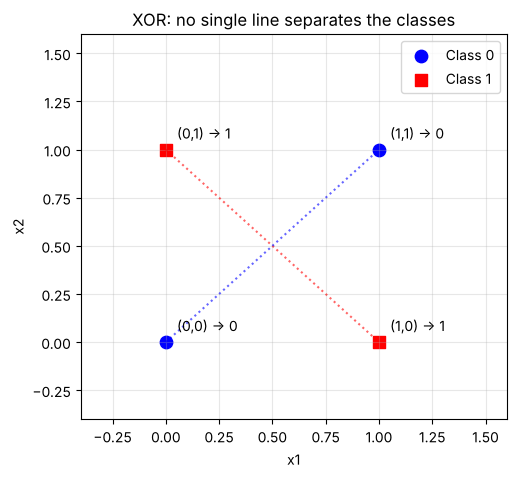

In [16]:
# Q3(b) - XOR is not linearly separable
fig, ax = plt.subplots(figsize=(5.5, 5))
scatter_classes(ax, X_gate, y_xor, ("Class 0", "Class 1"))
ax.plot([0, 1], [1, 0], "r:", alpha=0.6)     # class-1 diagonal
ax.plot([0, 1], [0, 1], "b:", alpha=0.6)     # class-0 diagonal (the two diagonals cross)
for (px, py), lab in zip(X_gate, y_xor):
    ax.annotate(f"({px},{py}) -> {lab}", (px, py), textcoords="offset points", xytext=(8, 8))
ax.set_xlim(-0.4, 1.6); ax.set_ylim(-0.4, 1.6)
ax.set_title("XOR: no single line separates the classes")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

**Q4 [1.5 marks] — Iris extension.** Add sepal length (feature 0) so you use features (0, 2, 3). Retrain the Part 5 model; report accuracy and macro-F1. Does the extra feature help? Support your answer with numbers.

In [17]:
# Q4
def run_iris(features):
    X = iris.data[:, features]
    Xtr, Xte, ytr, yte = train_test_split(X, y_iris, test_size=0.3, random_state=42, stratify=y_iris)
    m = Perceptron(random_state=42).fit(Xtr, ytr)
    p = m.predict(Xte)
    return accuracy_score(yte, p), f1_score(yte, p, average="macro"), int((p != yte).sum()), m

print(f"{'Features':<12} | {'Accuracy':>8} | {'Macro-F1':>8} | {'Errors':>6}")
print("-" * 46)
for feats in [(2, 3), (0, 2, 3)]:
    acc, f1, err, m_ = run_iris(list(feats))
    print(f"{str(feats):<12} | {acc:>8.3f} | {f1:>8.3f} | {err:>6}")
    print("   coef_:", np.round(m_.coef_[0], 3), " intercept_:", np.round(m_.intercept_, 3))

Features     | Accuracy | Macro-F1 | Errors
----------------------------------------------
(2, 3)       |    1.000 |    1.000 |      0
   coef_: [-1.3 -2.2]  intercept_: [4.]
(0, 2, 3)    |    1.000 |    1.000 |      0
   coef_: [ 4.5 -8.7 -4.1]  intercept_: [2.]


**Analysis:** Using features (2, 3) the model scores accuracy = 1.000 and macro-F1 = 1.000 (0 errors); adding sepal length (features 0, 2, 3) gives exactly the same accuracy = 1.000 and macro-F1 = 1.000 (0 errors). So the extra feature does **not** help — it only changes the weights (coef_ [4.5, −8.7, −4.1], intercept 2.0) — because petal length and width already separate Setosa from the rest perfectly, leaving no room for improvement.

**Q5 [1.5 marks] — Synthetic data.** `make_classification(n_samples=200, n_features=2, n_redundant=0, n_clusters_per_class=1, random_state=42)`, 70/30 split. Train your hand-built perceptron and sklearn's. Compare accuracy, epochs, final w and b; plot both boundaries side by side.

Model          | Test acc | Epochs | w                       | b
----------------------------------------------------------------------
Hand-built     |    0.633 |   1000 | [ 0.135 -0.069]          | 0.200
sklearn        |    0.667 |      6 | [2.281 0.58 ]            | 2.000
Reference - Logistic Regression test acc: 0.867 (shows the data is not linearly separable)
Hand-built final-epoch mistakes: 30 (did not reach 0)


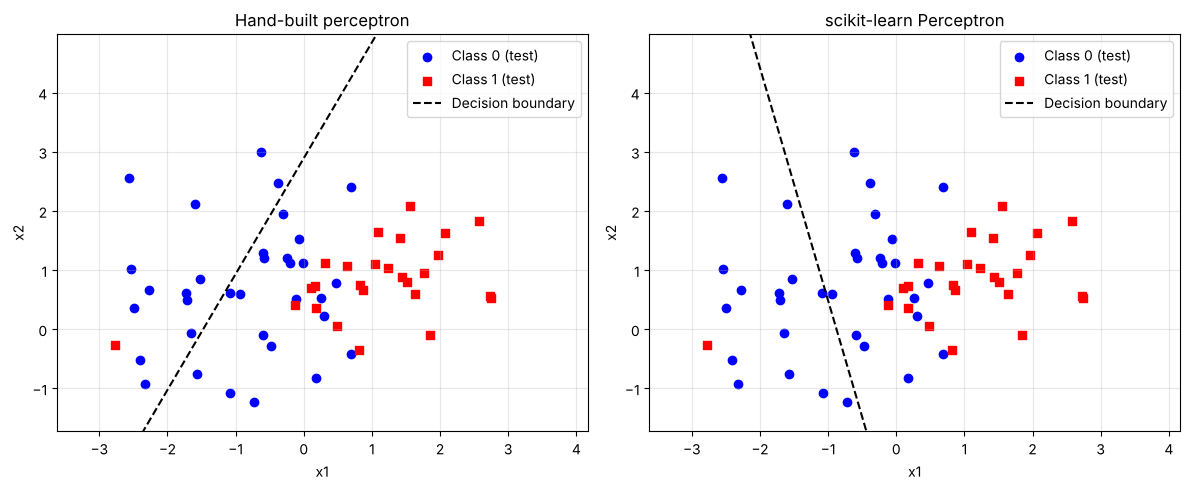

In [18]:
# Q5
Xs, ys = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, random_state=42)
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=42)

# Hand-built perceptron
w_h, b_h, m_h = train_perceptron(Xs_tr, ys_tr, eta=0.1, max_epochs=1000)
pred_h = (Xs_te @ w_h + b_h >= 0).astype(int)

# scikit-learn perceptron
sk = Perceptron(random_state=42).fit(Xs_tr, ys_tr)
pred_s = sk.predict(Xs_te)

print(f"{'Model':<14} | {'Test acc':>8} | {'Epochs':>6} | w{'':<22} | b")
print("-" * 70)
print(f"{'Hand-built':<14} | {accuracy_score(ys_te, pred_h):>8.3f} | {len(m_h):>6} | {str(np.round(w_h, 3)):<24} | {b_h:.3f}")
print(f"{'sklearn':<14} | {accuracy_score(ys_te, pred_s):>8.3f} | {sk.n_iter_:>6} | {str(np.round(sk.coef_[0], 3)):<24} | {sk.intercept_[0]:.3f}")
lr_ref = LogisticRegression(random_state=42).fit(Xs_tr, ys_tr)
print("Reference - Logistic Regression test acc:", round(lr_ref.score(Xs_te, ys_te), 3), "(shows the data is not linearly separable)")
print("Hand-built final-epoch mistakes:", m_h[-1], "(converged)" if m_h[-1] == 0 else "(did not reach 0)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
xr = (Xs[:, 0].min() - 0.5, Xs[:, 0].max() + 0.5)
for ax, title, (w_, b_) in zip(axes, ["Hand-built perceptron", "scikit-learn Perceptron"],
                               [(w_h, b_h), (sk.coef_[0], sk.intercept_[0])]):
    ax.scatter(Xs_te[ys_te == 0, 0], Xs_te[ys_te == 0, 1], c="blue", marker="o", label="Class 0 (test)")
    ax.scatter(Xs_te[ys_te == 1, 0], Xs_te[ys_te == 1, 1], c="red", marker="s", label="Class 1 (test)")
    plot_boundary(ax, w_, b_, x_range=xr)
    ax.set_xlim(*xr); ax.set_ylim(Xs[:, 1].min() - 0.5, Xs[:, 1].max() + 0.5)
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Analysis:** The hand-built perceptron reaches only **63.3 %** test accuracy after all 1000 epochs, with final w = [0.135, −0.069], b = 0.2 and still 30 mistakes in its last epoch (it never converged); scikit-learn's perceptron stops after **6 epochs** with **66.7 %** accuracy, w = [2.281, 0.58], b = 2.0. The two boundaries differ noticeably, and both are poor because the two classes overlap and are **not linearly separable** (a logistic regression reference reaches about 86.7 % test accuracy, so even the best line makes errors). The perceptron convergence theorem therefore does not apply: the hand-built version keeps updating and its final weights are just wherever it stopped, while scikit-learn shuffles the data and stops early once its loss stops improving (`tol`), giving different but similarly weak results.